# 102장 · POST 요청·응답 계약과 저장 상태

API의 요청·응답 계약에는 성공만 담지 않습니다. 답은 만들었지만 저장하지 못한 경우를 호출자가 알아볼 수 있도록 결과를 나눕니다.

팀의 조회 함수는 이미 Q01에 답합니다. 화면에서 같은 기능을 쓰려면 요청에 대화를 식별할 값과 이번 질문을 식별할 값이 함께 있어야 합니다. 요청 하나와 응답 하나로 화면과 서비스 사이의 약속을 정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## POST /p1/ask의 JSON 요청

준비 계약은 session_id·request_id·question 세 문자열을 받습니다. 수업 주체는 준비한 헤더나 서버의 검사 설정으로 결정합니다. 질문 본문에 적은 권한을 서버가 믿어서는 안 됩니다. 유효한 대화를 먼저 만든 뒤 다음 요청을 보낸다는 설정입니다.


### 셀 01 · POST 요청 JSON 직렬화

준비된 정상 사례의 대화 lesson, 요청 normal에 정확히 어떤 문장이 실리는지 확인합니다.


In [1]:
import json
request = {"session_id": "lesson", "request_id": "normal",
           "question": "장비 A의 점검 전 확인 사항은?"}
print(json.dumps(request, ensure_ascii=False))

{"session_id": "lesson", "request_id": "normal", "question": "장비 A의 점검 전 확인 사항은?"}


세 필드가 한 요청으로 묶입니다. session_id는 대화를 찾고 request_id는 해당 시도를 추적합니다. 이 셀은 전송 전의 JSON을 만들었습니다.


### HTTP 200에서 실제 답과 출처 ID까지 내려가기

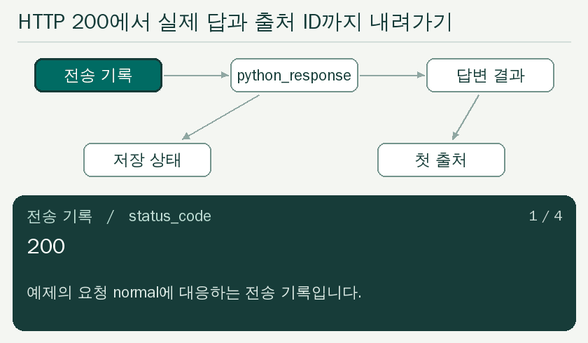

저장된 전송 예시의 겉 상태와 안쪽 값을 읽는 경로입니다. HTTP 상태 코드만으로 인용한 문서까지 알 수는 없습니다.


### 셀 02 · 응답의 출처 필드

로컬 전송 기록 정상 행에서 화면이 읽을 필드만 발췌했습니다. 실제 응답 원본에는 job 등 추가 필드도 있습니다.


In [2]:
transport_row = {'status_code': 200,
 'body': {'contract_version': 'P1-H1-prepared-v1',
          'result_kind': 'P1',
          'python_response': {'request_id': 'normal',
                              'session_id': 'lesson',
                              'boundary_status': 'ok',
                              'workflow_status': 'completed',
                              'result': {'status': 'answered',
                                         'answer': '점검 전 전원 표시등을 확인합니다.',
                                         'sources': [{'id': 'RULE-A',
                                                      'text': '점검 전 전원 '
                                                              '표시등을 확인합니다.',
                                                      'source': '가상 장비실 규정 '
                                                                'A',
                                                      'page': 1,
                                                      'section': '2.1',
                                                      'revised_on': '2026-11-01',
                                                      'version': 'rules-v1'}],
                                         'mode': 'local_rule_fixture',
                                         'model_calls': 0},
                              'storage_status': 'committed',
                              'error': None}}}
payload = transport_row["body"]["python_response"]
print(transport_row["status_code"], payload["result"]["status"], payload["storage_status"])
print(payload["result"]["sources"][0]["id"])

200 answered committed
RULE-A


기록에는 200·answered·committed와 RULE-A가 있습니다. 200은 준비 코드의 전송 상태, answered는 질문 처리 결과, committed는 저장 결과입니다. 어느 하나만 보고 나머지를 추정하지 않습니다.


## 답변 생성과 저장 성공 여부 구분

응답 예시　대화 lesson / 요청 unsaved / 로컬 전송 상태 503 / 업무 답 장비 B의 고정 장치 / 오류 코드 storage_failure. 이 경우 “관련 문서가 없습니다”라고 표시하면 다음 행동을 고르기 어렵습니다. 이전 요청이 저장되었는지 먼저 확인하도록 안내합니다.

<!-- lesson-visual visual-storage -->
**답변은 만들어졌는데 저장은 실패할 수 있습니다**

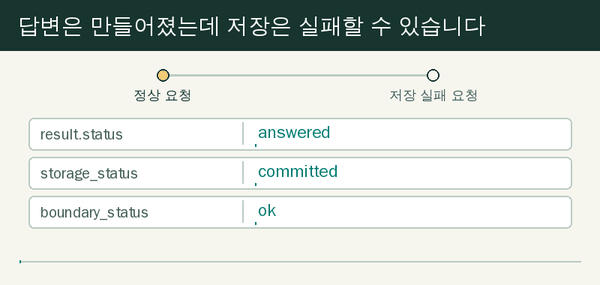

두 요청 모두 답변을 만들었습니다. 두 번째 요청의 처리 경계에서 저장 실패가 관찰되므로 answered 하나만 보고 저장 완료를 표시할 수 없습니다.
<!-- /lesson-visual visual-storage -->


### 과제 03 · 선택 연습 · 답변 생성 후 저장 실패

기록에서 계산한 답과 저장 오류명을 꺼내어 담당자가 확인할 두 줄을 만드세요.

failed는 로컬에 제공한 503 기록에서 python_response에 해당하는 부분만 꺼낸 값입니다. 여기서는 result부터 읽습니다. 앞의 기록 전체에서 시작할 때만 body와 python_response를 먼저 거치세요.


In [3]:
failed = {'request_id': 'unsaved',
 'session_id': 'lesson',
 'boundary_status': 'storage_error',
 'workflow_status': 'completed',
 'result': {'status': 'answered',
            'answer': '점검 전 고정 장치를 확인합니다.',
            'sources': [{'id': 'RULE-B',
                         'text': '점검 전 고정 장치를 확인합니다.',
                         'source': '가상 장비실 규정 B',
                         'page': 2,
                         'section': '2.2',
                         'revised_on': '2026-11-01',
                         'version': 'rules-v1'}],
            'mode': 'local_rule_fixture',
            'model_calls': 0},
 'storage_status': 'failed',
 'error': {'code': 'storage_failure',
           'stage': 'session_commit',
           'error_type': 'OSError'}}
# result 안의 답과 error 안의 code를 각각 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>failed = {&#x27;request_id&#x27;: &#x27;unsaved&#x27;,
 &#x27;session_id&#x27;: &#x27;lesson&#x27;,
 &#x27;boundary_status&#x27;: &#x27;storage_error&#x27;,
 &#x27;workflow_status&#x27;: &#x27;completed&#x27;,
 &#x27;result&#x27;: {&#x27;status&#x27;: &#x27;answered&#x27;,
            &#x27;answer&#x27;: &#x27;점검 전 고정 장치를 확인합니다.&#x27;,
            &#x27;sources&#x27;: [{&#x27;id&#x27;: &#x27;RULE-B&#x27;,
                         &#x27;text&#x27;: &#x27;점검 전 고정 장치를 확인합니다.&#x27;,
                         &#x27;source&#x27;: &#x27;가상 장비실 규정 B&#x27;,
                         &#x27;page&#x27;: 2,
                         &#x27;section&#x27;: &#x27;2.2&#x27;,
                         &#x27;revised_on&#x27;: &#x27;2026-11-01&#x27;,
                         &#x27;version&#x27;: &#x27;rules-v1&#x27;}],
            &#x27;mode&#x27;: &#x27;local_rule_fixture&#x27;,
            &#x27;model_calls&#x27;: 0},
 &#x27;storage_status&#x27;: &#x27;failed&#x27;,
 &#x27;error&#x27;: {&#x27;code&#x27;: &#x27;storage_failure&#x27;,
           &#x27;stage&#x27;: &#x27;session_commit&#x27;,
           &#x27;error_type&#x27;: &#x27;OSError&#x27;}}
print(failed[&quot;result&quot;][&quot;answer&quot;])
print(failed[&quot;error&quot;][&quot;code&quot;])</code></pre>
<p>실행 결과</p><pre><code>점검 전 고정 장치를 확인합니다.
storage_failure</code></pre>
<p>고정 장치 답과 storage_failure가 함께 남습니다. 503이라고 해서 계산 결과까지 사라진 것은 아닙니다.</p>
</details>


## 돌아보기

103장에는 정상 Q01과 저장 실패 요청의 상태·출처를 함께 넘깁니다. 이 장은 요청과 로컬 전송 자료를 노트북에서 읽습니다. 실제 HTTP 응답, DB와 인증 결과는 이 실행으로 확인할 수 없습니다.
